# 98 — Scorecard: every change, one table

Every change tested in the v1–v7 notebooks, with its **paired, same-fold effect** against the row it was compared to. Nothing is re-run here: the notebook only reads `results.jsonl`.

**How to read the columns**
- **Δ acc** — mean over the 5 folds of (test row − reference row), fold by fold, so fold difficulty cancels out.
- **folds ↑** — in how many of the 5 folds the change was positive. 5/5 or 0/5 is a *consistent* direction.
- **t (paired)** — Δ ÷ (sd of the 5 fold differences ÷ √5). With 5 folds the 5% cut is |t| ≈ 2.8. **Caveat:** CV folds share training data, so this t is *over*-confident. Treat 'helps' / 'hurts' as 'worth a leaderboard check', and 'noise' as 'no evidence'.
- **verdict** — `helps` / `hurts` only when **both** |t| > 2.8 **and** |Δ| ≥ 0.002 (about half a fold std; 0.002 ≈ 120 pumps out of 59,400). `tiny` = a consistent direction but too small to matter or to trust (|t| > 2.8, |Δ| < 0.002). Otherwise `noise`.

In [1]:
import sys, warnings, json
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 60)
R = {(r['version'], r['label']): r for r in map(json.loads, RESULTS.read_text().splitlines())}
def row(v, prefix):
    hits = [r for (vv, l), r in R.items() if vv == v and l.startswith(prefix)]
    assert len(hits) == 1, (v, prefix, len(hits)); return hits[0]
# (version, change, kind, test-row prefix, reference-row prefix) -- reference = the row the notebook itself compared against
SPEC = [
 ('v1', 'drop the leaky feature fit (fit per fold)',       'protocol', ('v1', 'A1'),  ('v1', 'A0')),
 ('v1', 'drop top-15 mutual-information cut',              'removal',  ('v1', 'A2'),  ('v1', 'A1')),
 ('v2', 'native categoricals (no freq-encode, no top-15)', 'feature',  ('v2', '+B'),  ('v2', 'A ')),
 ('v2', 'region-median imputation',                        'feature',  ('v2', '+C'),  ('v2', '+B')),
 ('v2', 'missingness flags',                               'feature',  ('v2', '+D'),  ('v2', '+C')),
 ('v2', 'v2 hand-picked XGBoost params',                   'model',    ('v2', '+E'),  ('v2', '+D')),
 ('v2', 'balanced class weights',                          'model',    ('v2', '+F'),  ('v2', '+E')),
 ('v2', 'latitude-placeholder fix (with weights)',         'bugfix',   ('v2', '+G'),  ('v2', '+F')),
 ('v3', 'searched hyperparameters (vs v2 hand params)',    'model',    ('v3', '3a'),  ('v2', '+E')),
 ('v3', 'early stopping (honest) vs fixed 300 trees',      'model',    ('v3', '3c'),  ('v3', '3a')),
 ('v3', 'balanced weights (honest ES)',                    'model',    ('v3', '3e'),  ('v3', '3c')),
 ('v4', 'geo_cluster k=30',                                'feature',  ('v4', '4a'),  ('v3', '3a')),
 ('v4', 'geo_cluster k=10',                                'feature',  ('v4', '4b'),  ('v3', '3a')),
 ('v4', 'geo_cluster k=60',                                'feature',  ('v4', '4c'),  ('v3', '3a')),
 ('v4', 'latitude fix alone (no weights)',                 'bugfix',   ('v4', '4e'),  ('v3', '3a')),
 ('v4', 'latitude fix with geo_cluster',                   'bugfix',   ('v4', '4d'),  ('v4', '4a')),
 ('v5', 'lowercase/strip funder+installer',                'feature',  ('v5', '5a'),  ('v4', '4a')),
 ('v5', 'collapse rare levels < 20 (v5)',                  'feature',  ('v5', '5b'),  ('v4', '4a')),
 ('v5', 'collapse rare levels < 5',                        'feature',  ('v5', '5c'),  ('v4', '4a')),
 ('v5', 'collapse rare levels < 100',                      'feature',  ('v5', '5d'),  ('v4', '4a')),
 ('v5', 'also collapse ward + lga',                        'feature',  ('v5', '5e'),  ('v5', '5b')),
 ('v5', 'DROP funder + installer',                         'removal',  ('v5', '5f'),  ('v4', '4a')),
 ('v6', 'all three interactions (v6)',                     'feature',  ('v6', '6a'),  ('v5', '5b')),
 ('v6', 'quantity x waterpoint_type',                      'feature',  ('v6', '6b'),  ('v5', '5b')),
 ('v6', 'payment x management',                            'feature',  ('v6', '6c'),  ('v5', '5b')),
 ('v6', 'population_density_ratio',                        'feature',  ('v6', '6d'),  ('v5', '5b')),
 ('v7', 'LightGBM alone vs XGBoost alone',                 'model',    ('v7', '7a lgbm'),  ('v7', '7a xgb')),
 ('v7', 'XGB+LGBM blend vs XGBoost alone (honest)',        'model',    ('v7', '7a blend'), ('v7', '7a xgb')),
 ('v7', 'blend with num_leaves=255 LightGBM vs XGB alone', 'model',    ('v7', '7b blend'), ('v7', '7b xgb')),
]
rows = []
for v, change, kind, t, r in SPEC:
    a, b = row(*t), row(*r)
    d = np.array(a['folds']) - np.array(b['folds'])
    se = d.std(ddof=1) / np.sqrt(len(d)); tt = d.mean() / se if se > 0 else np.nan
    big = abs(d.mean()) >= 0.002          # practical size: about half a fold std of accuracy (~0.004)
    verdict = ('helps' if d.mean() > 0 else 'hurts') if (abs(tt) > 2.8 and big) else ('tiny' if abs(tt) > 2.8 else 'noise')
    rows.append({'ver': v, 'change': change, 'kind': kind, 'acc': round(a['mean'], 4), 'Δ acc': round(d.mean(), 4),
                 'folds ↑': f'{(d > 0).sum()}/5', 't (paired)': round(tt, 1), 'verdict': verdict})
S = pd.DataFrame(rows)
S

,ver,change,kind,acc,Δ acc,folds ↑,t (paired),verdict
0,v1,drop the leaky feature fit (fit per fold),protocol,0.8034,-0.0003,3/5,-0.2,noise
1,v1,drop top-15 mutual-information cut,removal,0.8090,0.0056,5/5,9.6,helps
2,v2,"native categoricals (no freq-encode, no top-15)",feature,0.8010,-0.0024,2/5,-2.0,noise
3,v2,region-median imputation,feature,0.8005,-0.0005,2/5,-0.8,noise
4,v2,missingness flags,feature,0.8008,0.0003,2/5,0.4,noise
5,v2,v2 hand-picked XGBoost params,model,0.7979,-0.0029,0/5,-2.4,noise
6,v2,balanced class weights,model,0.7772,-0.0206,0/5,-23.3,hurts
7,v2,latitude-placeholder fix (with weights),bugfix,0.7766,-0.0006,1/5,-0.7,noise
8,v3,searched hyperparameters (vs v2 hand params),model,0.8110,0.0131,5/5,8.6,helps
9,v3,early stopping (honest) vs fixed 300 trees,model,0.8106,-0.0005,2/5,-0.8,noise


## Which kinds of change mattered?

In [2]:
g = S.groupby('kind').agg(changes=('change', 'count'), helps=('verdict', lambda s: (s == 'helps').sum()),
                          hurts=('verdict', lambda s: (s == 'hurts').sum()), mean_abs_Δ=('Δ acc', lambda s: s.abs().mean().round(4)))
g

,changes,helps,hurts,mean_abs_Δ
kind,,,,
bugfix,3,0,0,0.0004
feature,15,0,0,0.0006
model,8,1,3,0.0101
protocol,1,0,0,0.0003
removal,2,1,1,0.0038


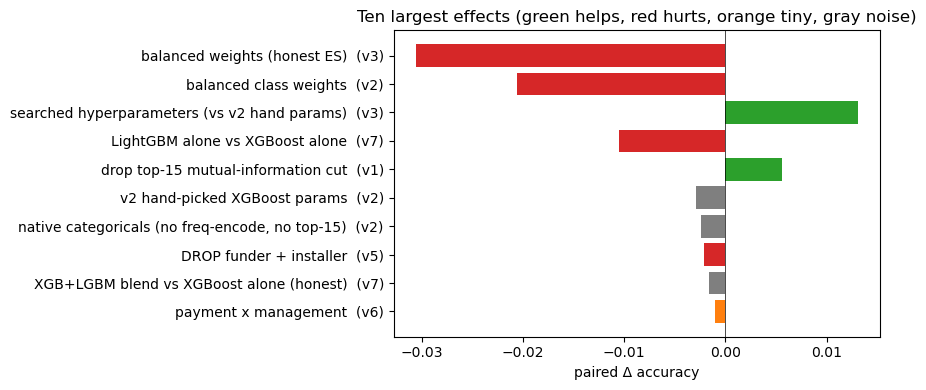

In [3]:
top = S.reindex(S['Δ acc'].abs().sort_values(ascending=False).index).head(10)
fig, ax = plt.subplots(figsize=(9, 4))
colors = top.verdict.map({'helps': 'tab:green', 'hurts': 'tab:red', 'tiny': 'tab:orange', 'noise': 'tab:gray'})
ax.barh(top.change + '  (' + top.ver + ')', top['Δ acc'], color=colors); ax.invert_yaxis(); ax.axvline(0, c='k', lw=.5)
ax.set_xlabel('paired Δ accuracy'); ax.set_title('Ten largest effects (green helps, red hurts, orange tiny, gray noise)')
plt.tight_layout(); plt.show()

## Reading the scorecard

29 changes were tested across v1–v7. Only five clear **both** bars (consistent *and* ≥ 0.002):

| change | Δ acc | verdict |
|---|---|---|
| drop the top-15 MI cut (v1) | +0.0056 | helps, 5/5 folds |
| searched hyperparameters vs v2's hand-picked ones (v3) | +0.0131 | helps, 5/5 folds. *But v2's hand params were themselves worse than v1's untuned ones, so against v1's 0.8090 the gain is only ~+0.002* |
| balanced class weights (v2, v3) | −0.021, −0.031 | **hurts**, 0/5 folds, the largest effects in the project |
| drop `funder` + `installer` (v5) | −0.0021 | hurts, so the columns carry a little signal |
| LightGBM at v7's mapping vs XGBoost (v7) | −0.0105 | hurts, an artefact of `num_leaves=31` |

- **Not one engineered feature helps.** All 15 feature changes (native categoricals, region imputation, missingness flags, `geo_cluster` at three k, text cleaning at four settings, three interactions) have **zero** `helps` and **zero** `hurts`. Two (`geo_cluster` k=10 and k=60) and one negative (`payment × management`) are consistent in direction but ≤ 0.001, so `tiny`: about 50 pumps out of 59,400, and I would not trust them from one seed.
- **What moved accuracy was model and protocol, not features.** Of the 8 model-level changes, 4 are decisive, and the biggest, by far, is *removing* something (the class weights).
- **Bug fixes: nothing.** The latitude-placeholder bug is real (1,812 rows) and its fix is neutral in all three tests.
- **Caveat on the test itself.** The paired t over-states confidence because CV folds share training rows, which is why I added the size floor. Treat `helps`/`hurts` as "worth a leaderboard check", `tiny`/`noise` as "no evidence".

Mapping to the original hypotheses from `00_data`: H1 (latitude) ✗, H2 (native categoricals) ✗, H3 (region imputation) ✗, H4 (flags) ✗, H5 (weights help the metric) ✗ (reversed), H6 (search + ES) ◐ (search yes vs v2's params, ES no), H7 (cluster / text / interactions) ✗, H8 (blend) ✗.